In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/aishwaryalpujeri/cardio-dataset/cardio_train.csv


## PART 1 — Import libraries

In [2]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import glob
import json
import shutil
import joblib
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Find the Kaggle dataset

In [3]:
# ============================================================
# 2. FIND DATASET
# ============================================================

csv_files = glob.glob(
    "/kaggle/input/**/*.csv",
    recursive=True
)

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found. Add the Kaggle dataset first."
    )

print("CSV files found:")

for file in csv_files:
    print(file)

# Find cardio_train.csv
matches = [
    file for file in csv_files
    if "cardio_train" in os.path.basename(file).lower()
]

if matches:
    DATA_PATH = matches[0]
else:
    DATA_PATH = csv_files[0]

print("\nUsing dataset:")
print(DATA_PATH)

CSV files found:
/kaggle/input/datasets/aishwaryalpujeri/cardio-dataset/cardio_train.csv

Using dataset:
/kaggle/input/datasets/aishwaryalpujeri/cardio-dataset/cardio_train.csv


## 3. Load dataset automatically

In [4]:
# ============================================================
# 3. LOAD DATASET
# ============================================================

df = pd.read_csv(
    DATA_PATH,
    sep=";"
)

# Clean column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
)

print("Dataset loaded successfully!")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Rows: 70000
Columns: 13

Columns:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


## 4. Basic dataset inspection

In [5]:
# ============================================================
# 4. DATASET INFORMATION
# ============================================================

print("Dataset shape:", df.shape)

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())


Dataset shape: (70000, 13)

Data types:


id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object


Missing values:


id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


Duplicate rows:
0

Statistical summary:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
# ============================================================
# 5. TARGET VALIDATION
# ============================================================

TARGET = "cardio"

if TARGET not in df.columns:
    raise ValueError(
        f"Target '{TARGET}' not found.\n"
        f"Available columns: {df.columns.tolist()}"
    )

print("Target:", TARGET)

print("\nTarget counts:")
display(
    df[TARGET].value_counts()
)

print("\nTarget percentages:")
display(
    df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target: cardio

Target counts:


cardio
0    35021
1    34979
Name: count, dtype: int64


Target percentages:


cardio
0    50.03
1    49.97
Name: proportion, dtype: float64

In [7]:
# ============================================================
# 6. REMOVE DUPLICATES
# ============================================================

before = len(df)

df = df.drop_duplicates()

df = df.reset_index(drop=True)

after = len(df)

print("Rows before:", before)
print("Rows after:", after)

print("Duplicates removed:", before - after)

Rows before: 70000
Rows after: 70000
Duplicates removed: 0


In [8]:
# ============================================================
# 7. CHECK EXTREME VALUES
# ============================================================

print("Height range:")
print(df["height"].min(), "to", df["height"].max())

print("\nWeight range:")
print(df["weight"].min(), "to", df["weight"].max())

print("\nSystolic BP range:")
print(df["ap_hi"].min(), "to", df["ap_hi"].max())

print("\nDiastolic BP range:")
print(df["ap_lo"].min(), "to", df["ap_lo"].max())

Height range:
55 to 250

Weight range:
10.0 to 200.0

Systolic BP range:
-150 to 16020

Diastolic BP range:
-70 to 11000


In [9]:
# ============================================================
# 8. CLEAN INVALID / EXTREME VALUES
# ============================================================

print("Before cleaning:", df.shape)

# Age: 18-100 years
df = df[
    (df["age"] >= 18 * 365) &
    (df["age"] <= 100 * 365)
]

# Height: reasonable adult range
df = df[
    (df["height"] >= 120) &
    (df["height"] <= 220)
]

# Weight: reasonable range
df = df[
    (df["weight"] >= 30) &
    (df["weight"] <= 250)
]

# Systolic BP
df = df[
    (df["ap_hi"] >= 70) &
    (df["ap_hi"] <= 250)
]

# Diastolic BP
df = df[
    (df["ap_lo"] >= 40) &
    (df["ap_lo"] <= 150)
]

# Logical BP relationship
df = df[
    df["ap_lo"] < df["ap_hi"]
]

# Valid target
df = df[
    df["cardio"].isin([0, 1])
]

df = df.reset_index(drop=True)

print("After cleaning:", df.shape)

print(
    f"Removed {70000 - len(df):,} records from the original dataset."
)

Before cleaning: (70000, 13)
After cleaning: (68610, 13)
Removed 1,390 records from the original dataset.


In [10]:
# ============================================================
# 9. FEATURE ENGINEERING
# ============================================================

# Age in years
df["age_years"] = (
    df["age"] / 365.25
)

# BMI
height_m = df["height"] / 100

df["bmi"] = (
    df["weight"] / (height_m ** 2)
)

# Pulse pressure
df["pulse_pressure"] = (
    df["ap_hi"] - df["ap_lo"]
)

# Mean arterial pressure
df["mean_arterial_pressure"] = (
    df["ap_lo"] +
    (df["ap_hi"] - df["ap_lo"]) / 3
)

# Blood pressure ratio
df["bp_ratio"] = (
    df["ap_hi"] / df["ap_lo"]
)

print("Feature engineering completed.")

display(
    df[
        [
            "age_years",
            "bmi",
            "pulse_pressure",
            "mean_arterial_pressure",
            "bp_ratio"
        ]
    ].head()
)

Feature engineering completed.


,age_years,bmi,pulse_pressure,mean_arterial_pressure,bp_ratio
0,50.357290,21.967120,30,90.000000,1.375000
1,55.381246,34.927679,50,106.666667,1.555556
2,51.627652,23.507805,60,90.000000,1.857143
3,48.249144,28.710479,50,116.666667,1.500000
4,47.841205,23.011177,40,73.333333,1.666667


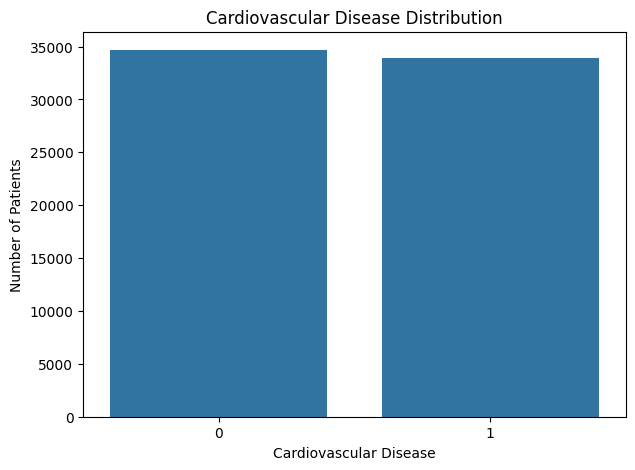

In [11]:
# ============================================================
# 10. TARGET DISTRIBUTION
# ============================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="cardio"
)

plt.title(
    "Cardiovascular Disease Distribution"
)

plt.xlabel(
    "Cardiovascular Disease"
)

plt.ylabel(
    "Number of Patients"
)

plt.show()

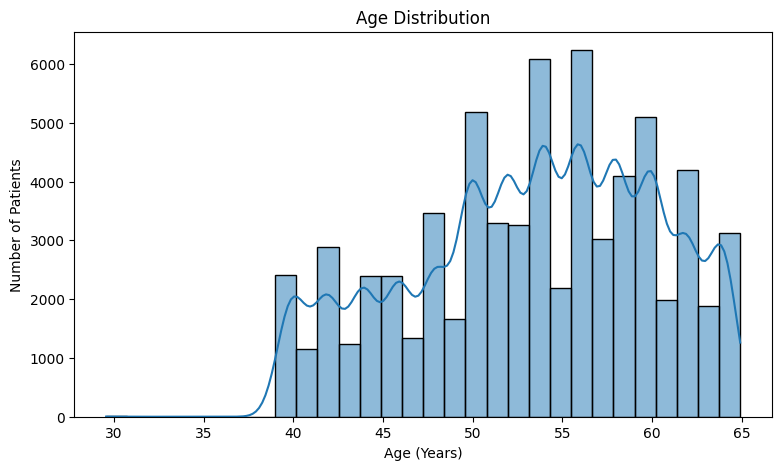

In [12]:
# ============================================================
# 11. AGE DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="age_years",
    bins=30,
    kde=True
)

plt.title("Age Distribution")

plt.xlabel("Age (Years)")
plt.ylabel("Number of Patients")

plt.show()

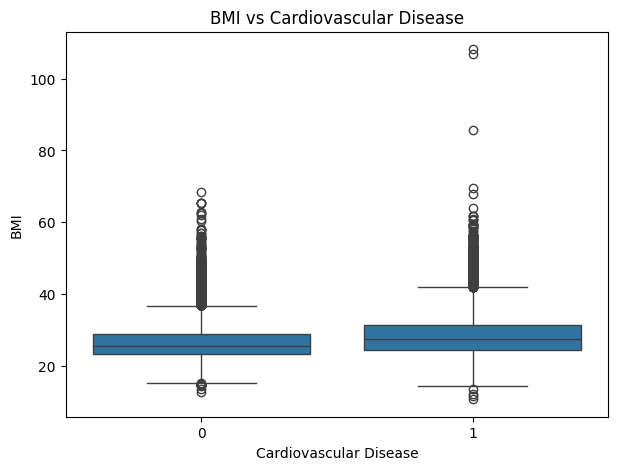

In [13]:
# ============================================================
# 12. BMI VS CARDIO
# ============================================================

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="cardio",
    y="bmi"
)

plt.title(
    "BMI vs Cardiovascular Disease"
)

plt.xlabel("Cardiovascular Disease")
plt.ylabel("BMI")

plt.show()

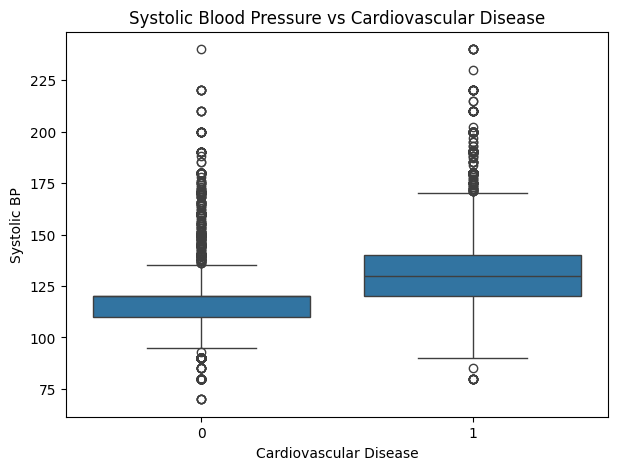

In [14]:
# ============================================================
# 13. BLOOD PRESSURE VS CARDIO
# ============================================================

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="cardio",
    y="ap_hi"
)

plt.title(
    "Systolic Blood Pressure vs Cardiovascular Disease"
)

plt.xlabel("Cardiovascular Disease")
plt.ylabel("Systolic BP")

plt.show()

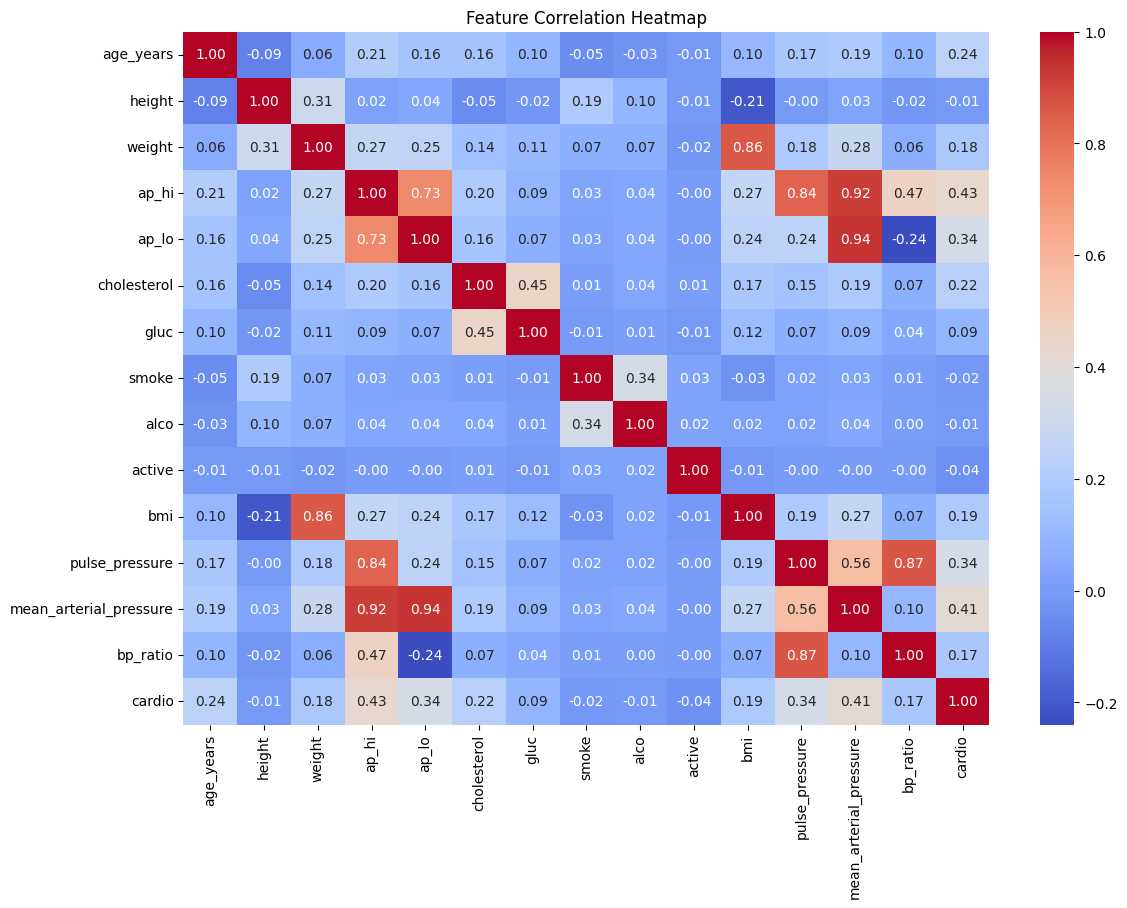

In [15]:
# ============================================================
# 14. CORRELATION HEATMAP
# ============================================================

corr_columns = [
    "age_years",
    "height",
    "weight",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "bmi",
    "pulse_pressure",
    "mean_arterial_pressure",
    "bp_ratio",
    "cardio"
]

plt.figure(figsize=(13, 9))

sns.heatmap(
    df[corr_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title(
    "Feature Correlation Heatmap"
)

plt.show()

In [16]:
# ============================================================
# 15. PREPARE FEATURES AND TARGET
# ============================================================

FEATURES = [
    "age_years",
    "height",
    "weight",
    "gender",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "bmi",
    "pulse_pressure",
    "mean_arterial_pressure",
    "bp_ratio"
]

X = df[FEATURES].copy()

y = df[TARGET].copy()

print("Features:", X.shape)

print("Target:", y.shape)

display(X.head())

Features: (68610, 15)
Target: (68610,)


,age_years,height,weight,gender,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,bmi,pulse_pressure,mean_arterial_pressure,bp_ratio
0,50.357290,168,62.0,2,110,80,1,1,0,0,1,21.967120,30,90.000000,1.375000
1,55.381246,156,85.0,1,140,90,3,1,0,0,1,34.927679,50,106.666667,1.555556
2,51.627652,165,64.0,1,130,70,3,1,0,0,0,23.507805,60,90.000000,1.857143
3,48.249144,169,82.0,2,150,100,1,1,0,0,1,28.710479,50,116.666667,1.500000
4,47.841205,156,56.0,1,100,60,1,1,0,0,0,23.011177,40,73.333333,1.666667


In [17]:
# ============================================================
# 16. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# 70% training
# 30% temporary

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

# Split remaining 30% into:
# 15% validation
# 15% test

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nTotal:", len(X_train) + len(X_val) + len(X_test))

Training: 48027
Validation: 10291
Test: 10292

Total: 68610


In [18]:
# ============================================================
# 17. PREPROCESSING PIPELINE
# ============================================================

numeric_features = [
    "age_years",
    "height",
    "weight",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "bmi",
    "pulse_pressure",
    "mean_arterial_pressure",
    "bp_ratio"
]

categorical_features = [
    "gender"
]

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline ready.")

Preprocessing pipeline ready.


In [19]:
# ============================================================
# 18. MACHINE LEARNING MODELS
# ============================================================

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=8,
            min_samples_split=10,
            random_state=RANDOM_STATE
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_split=5,
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

    "SVM":
        SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=RANDOM_STATE
        ),

    "KNN":
        KNeighborsClassifier(
            n_neighbors=15,
            weights="distance",
            n_jobs=-1
        )
}

print("Models created:")

for model_name in models:
    print("✓", model_name)

Models created:
✓ Logistic Regression
✓ Decision Tree
✓ Random Forest
✓ SVM
✓ KNN


In [20]:
# ============================================================
# 19. TRAIN ALL MODELS
# ============================================================

trained_models = {}

validation_results = []

for name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", name)
    print("=" * 60)

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    pipeline.fit(
        X_train,
        y_train
    )

    # Validation predictions
    val_pred = pipeline.predict(
        X_val
    )

    val_prob = pipeline.predict_proba(
        X_val
    )[:, 1]

    # Metrics
    accuracy = accuracy_score(
        y_val,
        val_pred
    )

    precision = precision_score(
        y_val,
        val_pred
    )

    recall = recall_score(
        y_val,
        val_pred
    )

    f1 = f1_score(
        y_val,
        val_pred
    )

    roc_auc = roc_auc_score(
        y_val,
        val_prob
    )

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": roc_auc
    })

    trained_models[name] = pipeline

    print(
        f"Accuracy : {accuracy:.4f}"
    )

    print(
        f"Precision: {precision:.4f}"
    )

    print(
        f"Recall   : {recall:.4f}"
    )

    print(
        f"F1 Score : {f1:.4f}"
    )

    print(
        f"ROC AUC  : {roc_auc:.4f}"
    )

print("\n✓ All models trained.")


Training: Logistic Regression
Accuracy : 0.7285
Precision: 0.7533
Recall   : 0.6710
F1 Score : 0.7097
ROC AUC  : 0.7920

Training: Decision Tree
Accuracy : 0.7314
Precision: 0.7449
Recall   : 0.6951
F1 Score : 0.7192
ROC AUC  : 0.7888

Training: Random Forest
Accuracy : 0.7329
Precision: 0.7485
Recall   : 0.6928
F1 Score : 0.7196
ROC AUC  : 0.7966

Training: SVM
Accuracy : 0.7339
Precision: 0.7598
Recall   : 0.6759
F1 Score : 0.7154
ROC AUC  : 0.7906

Training: KNN
Accuracy : 0.7173
Precision: 0.7201
Recall   : 0.7010
F1 Score : 0.7105
ROC AUC  : 0.7727

✓ All models trained.


In [21]:
# ============================================================
# 20. CREATE PROJECT DIRECTORIES
# ============================================================

PROJECT_DIR = (
    "/kaggle/working/"
    "cardiorisk_ai"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

print("Project directory:")
print(PROJECT_DIR)

print("\nModel directory:")
print(MODEL_DIR)

Project directory:
/kaggle/working/cardiorisk_ai

Model directory:
/kaggle/working/cardiorisk_ai/models


In [22]:
# ============================================================
# 21. SAVE ALL TRAINED MODELS
# ============================================================

for name, model in trained_models.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + ".joblib"
    )

    model_path = os.path.join(
        MODEL_DIR,
        filename
    )

    joblib.dump(
        model,
        model_path
    )

    print("Saved:", filename)

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: random_forest.joblib
Saved: svm.joblib
Saved: knn.joblib


In [23]:
# ============================================================
# 22. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(
    validation_results
)

results_df = results_df.sort_values(
    by="ROC AUC",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,0.7329,0.7485,0.6928,0.7196,0.7966
1,Logistic Regression,0.7285,0.7533,0.6710,0.7097,0.7920
2,SVM,0.7339,0.7598,0.6759,0.7154,0.7906
3,Decision Tree,0.7314,0.7449,0.6951,0.7192,0.7888
4,KNN,0.7173,0.7201,0.7010,0.7105,0.7727


In [24]:
# ============================================================
# 23. SAVE MODEL COMPARISON
# ============================================================

comparison_path = os.path.join(
    PROJECT_DIR,
    "model_comparison.csv"
)

results_df.to_csv(
    comparison_path,
    index=False
)

print("Saved:")
print(comparison_path)

Saved:
/kaggle/working/cardiorisk_ai/model_comparison.csv


In [25]:
# ============================================================
# 24. SELECT BEST MODEL
# ============================================================

best_model_name = (
    results_df
    .iloc[0]["Model"]
)

best_model = trained_models[
    best_model_name
]

print("🏆 BEST MODEL")
print("=" * 50)
print(best_model_name)

display(
    results_df.iloc[[0]]
)

🏆 BEST MODEL
Random Forest


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,0.732873,0.748514,0.692791,0.719576,0.796637


In [26]:
# ============================================================
# 25. SAVE BEST MODEL
# ============================================================

best_model_path = os.path.join(
    MODEL_DIR,
    "best_model.joblib"
)

joblib.dump(
    best_model,
    best_model_path
)

print("Best model saved:")
print(best_model_path)

Best model saved:
/kaggle/working/cardiorisk_ai/models/best_model.joblib


In [27]:
# ============================================================
# 26. FINAL TEST EVALUATION
# ============================================================

test_pred = best_model.predict(
    X_test
)

test_prob = best_model.predict_proba(
    X_test
)[:, 1]

test_accuracy = accuracy_score(
    y_test,
    test_pred
)

test_precision = precision_score(
    y_test,
    test_pred
)

test_recall = recall_score(
    y_test,
    test_pred
)

test_f1 = f1_score(
    y_test,
    test_pred
)

test_roc_auc = roc_auc_score(
    y_test,
    test_prob
)

print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print("Best Model :", best_model_name)

print(
    f"Accuracy   : {test_accuracy:.4f}"
)

print(
    f"Precision  : {test_precision:.4f}"
)

print(
    f"Recall     : {test_recall:.4f}"
)

print(
    f"F1 Score   : {test_f1:.4f}"
)

print(
    f"ROC-AUC    : {test_roc_auc:.4f}"
)

FINAL TEST RESULTS
Best Model : Random Forest
Accuracy   : 0.7400
Precision  : 0.7556
Recall     : 0.7012
F1 Score   : 0.7274
ROC-AUC    : 0.8032


In [28]:
# ============================================================
# 27. CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "No Cardiovascular Disease",
            "Cardiovascular Disease"
        ]
    )
)

                           precision    recall  f1-score   support

No Cardiovascular Disease       0.73      0.78      0.75      5201
   Cardiovascular Disease       0.76      0.70      0.73      5091

                 accuracy                           0.74     10292
                macro avg       0.74      0.74      0.74     10292
             weighted avg       0.74      0.74      0.74     10292



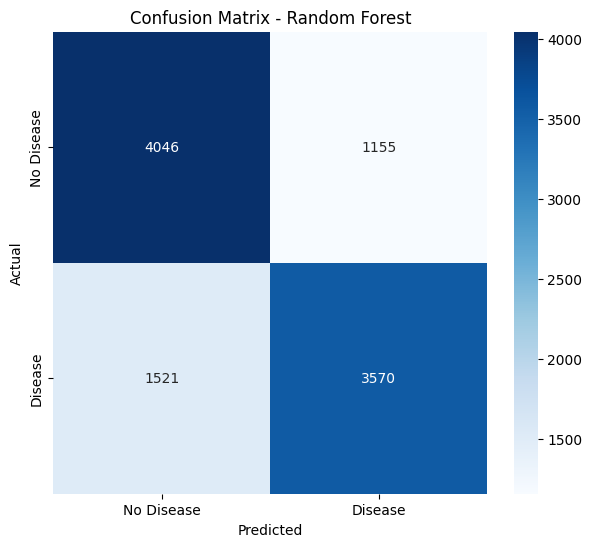

In [29]:
# ============================================================
# 28. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_pred
)

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Disease",
        "Disease"
    ],
    yticklabels=[
        "No Disease",
        "Disease"
    ]
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

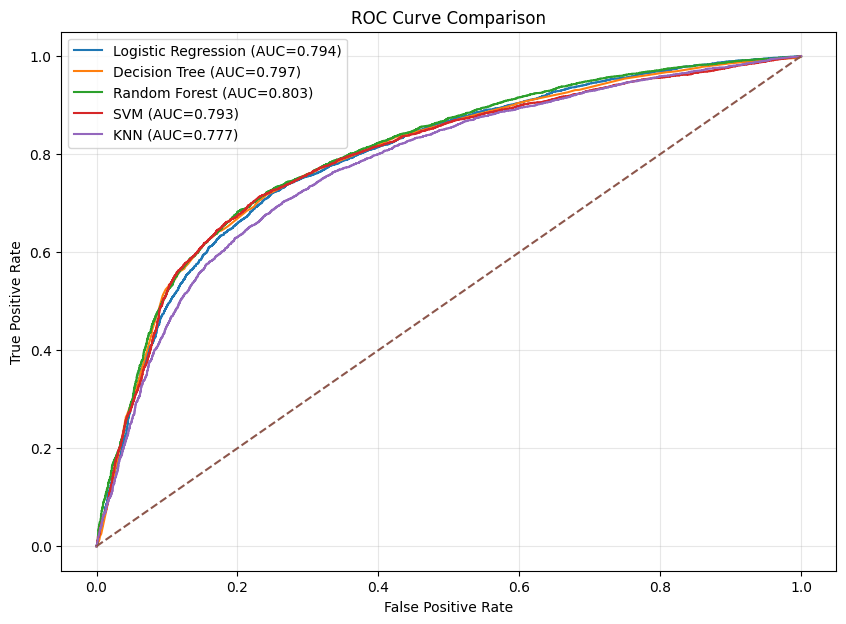

In [30]:
# ============================================================
# 29. ROC CURVE COMPARISON
# ============================================================

plt.figure(
    figsize=(10, 7)
)

for name, model in trained_models.items():

    probability = model.predict_proba(
        X_test
    )[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        probability
    )

    auc_score = roc_auc_score(
        y_test,
        probability
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve Comparison"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

In [31]:
# ============================================================
# 30. SAVE TEST PREDICTIONS
# ============================================================

test_predictions = pd.DataFrame({

    "actual": y_test.values,

    "predicted": test_pred,

    "probability": test_prob
})

test_path = os.path.join(
    PROJECT_DIR,
    "test_predictions.csv"
)

test_predictions.to_csv(
    test_path,
    index=False
)

print("Test predictions saved:")
print(test_path)

display(
    test_predictions.head(10)
)

Test predictions saved:
/kaggle/working/cardiorisk_ai/test_predictions.csv


,actual,predicted,probability
0,1,1,0.561243
1,1,1,0.834082
2,0,1,0.856310
3,1,0,0.073357
4,1,1,0.845865
5,1,0,0.313254
6,1,1,0.556022
7,0,0,0.239469
8,0,0,0.182289
9,1,1,0.885418


In [32]:
# ============================================================
# 31. SAVE MODEL METADATA
# ============================================================

metadata = {

    "project": "CardioRisk AI",

    "target": TARGET,

    "best_model": best_model_name,

    "selection_metric": "ROC AUC",

    "features": FEATURES,

    "train_records": len(X_train),

    "validation_records": len(X_val),

    "test_records": len(X_test),

    "test_accuracy": float(
        test_accuracy
    ),

    "test_precision": float(
        test_precision
    ),

    "test_recall": float(
        test_recall
    ),

    "test_f1": float(
        test_f1
    ),

    "test_roc_auc": float(
        test_roc_auc
    )
}

metadata_path = os.path.join(
    MODEL_DIR,
    "model_metadata.json"
)

with open(
    metadata_path,
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

print("Metadata saved.")

Metadata saved.


In [33]:
# ============================================================
# 33. CREATE REQUIREMENTS.TXT
# ============================================================

requirements = """streamlit
pandas
numpy
scikit-learn
joblib
matplotlib
seaborn
"""

requirements_path = os.path.join(
    PROJECT_DIR,
    "requirements.txt"
)

with open(
    requirements_path,
    "w"
) as f:

    f.write(
        requirements
    )

print(
    "requirements.txt created."
)

requirements.txt created.
